In [3]:
import folium
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN

In [4]:
inventory = pd.read_csv("./bottle_fillers_inventory.csv")
print(inventory.head())
inventory.dropna(subset=["X", "Y", "Z"], inplace=True)
inventory["coordinates"] = list(zip(inventory["X"].astype(int), inventory["Y"].astype(int), inventory["Z"].astype(int)))
print(inventory["coordinates"])

  Address A          Address B    Floor   \
0       100         Ashford St     First   
1       120         Ashford St     First   
2       120         Ashford St    Second   
3         8  St. Mary's Street  Basement   
4         8  St. Mary's Street     First   

                                         Description Accessibility  \
0  Hallway across from vending machines, across f...        Public   
1                             Kitchenette, Room 116A    Restricted   
2                              Kitchenette, Room 222    Restricted   
3                               Hallway by bathrooms           NaN   
4                         Hallway by electrical room           NaN   

  Handicap Accessible Space@Bu room  Quantity Date Installed  \
0                 Yes           191         1            NaN   
1                 Yes          116A         1            NaN   
2                 Yes           222         1            NaN   
3                 NaN           B81         1         Dec-

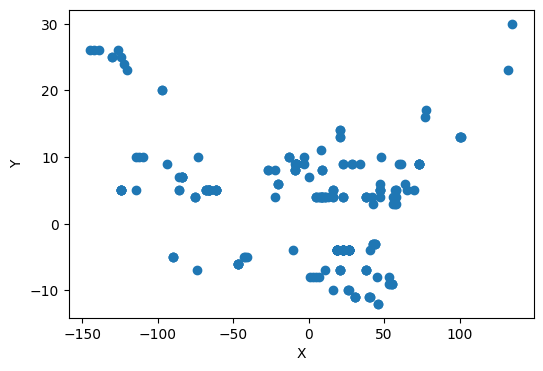

In [5]:
# 2D Plane
fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(111)
X = [coord[0] for coord in inventory["coordinates"]]
Y = [coord[1] for coord in inventory["coordinates"]]
ax.scatter(X, Y)

ax.set_xlabel("X")
ax.set_ylabel("Y")

plt.show()

Text(0.5, 0, 'Floor')

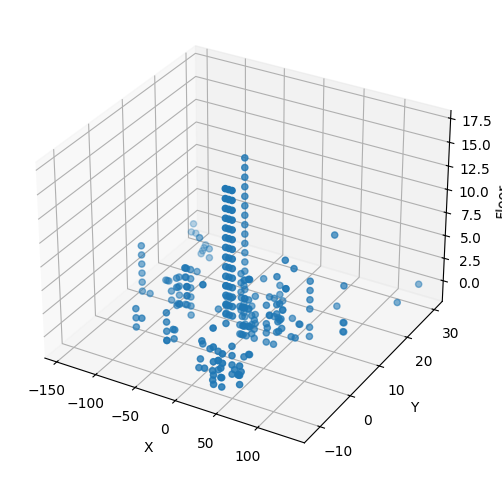

In [6]:
# 3D Plane
fig = plt.figure(figsize=(9,6))
ax = fig.add_subplot(111, projection="3d")
X = [coord[0] for coord in inventory["coordinates"]]
Y = [coord[1] for coord in inventory["coordinates"]]
Z = [coord[2] for coord in inventory["coordinates"]]
ax.scatter(X, Y, Z)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Floor")

In [7]:
dbscan = DBSCAN(eps=5, min_samples=1)
coordinates = list(zip(inventory["X"].astype(int), inventory["Y"].astype(int), inventory["Z"].astype(int)))
dbscan.fit(coordinates)
inventory["cluster_label"] = dbscan.labels_
print(inventory["cluster_label"].value_counts())

cluster_label
21    47
22    29
12    24
26    18
20    18
9     13
19     9
11     9
25     8
7      8
29     8
33     7
24     7
18     6
32     6
4      6
15     5
3      4
31     3
27     3
0      3
1      3
10     3
8      2
36     2
17     1
23     1
16     1
14     1
13     1
28     1
30     1
6      1
5      1
2      1
34     1
35     1
Name: count, dtype: int64


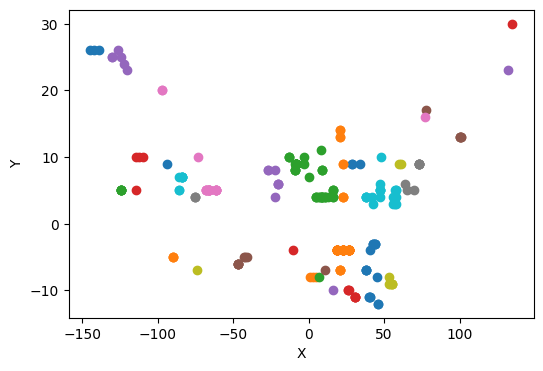

In [8]:
# 2D Representation of Clustering

fig = plt.figure(figsize=(6,4))
ax = fig.add_subplot(111)

for i, cluster_label in enumerate(np.unique(inventory["cluster_label"])):
    cluster_points = inventory[inventory["cluster_label"] == cluster_label]
    X = [coord[0] for coord in cluster_points["coordinates"]]
    Y = [coord[1] for coord in cluster_points["coordinates"]]
    ax.scatter(X, Y, label=f'Cluster {cluster_label}')

ax.set_xlabel("X")
ax.set_ylabel("Y")
plt.show()

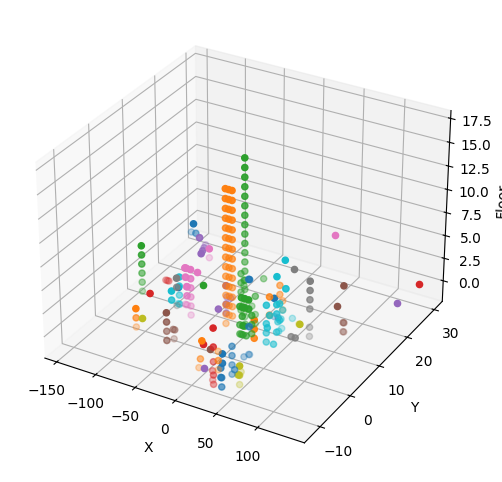

In [9]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")

for i, cluster_label in enumerate(np.unique(inventory["cluster_label"])):
    cluster_points = inventory[inventory["cluster_label"] == cluster_label]
    X = [coord[0] for coord in cluster_points["coordinates"]]
    Y = [coord[1] for coord in cluster_points["coordinates"]]
    Z = [coord[2] for coord in cluster_points["coordinates"]]
    ax.scatter(X, Y, Z, label=f'Cluster {cluster_label}')

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Floor")
plt.show()

In [18]:
origin = (42.350007280793704, -71.10658611283115)

m = folium.Map(location=[origin[0], origin[1]], zoom_start=15)

def convert_coords(lat, lon, center_lat, center_lon, angle):
    angle = np.deg2rad(angle)
    converted_lat, converted_lon = center_lat, center_lon
    lat_degrees, lon_degrees = degrees_per_meter(center_lat)

    lon_adj = lon * np.cos(angle)
    converted_lon += (lon_degrees * lon_adj * 10)

    # there are no x, y such that x = 0 or y = 0
    if lon > 0:
        if lat > 0:
            lat_adj = (lat * np.cos(angle)) - (lon * np.sin(angle))
            converted_lat += (lat_degrees * lat_adj * 10)
        if lat < 0:
            lat_adj = (lon * np.sin(angle)) + (abs(lat) * np.cos(angle))
            converted_lat -= (lat_degrees * lat_adj * 10)
    if lon < 0:
        if lat > 0:
            lat_adj = (lat * np.cos(angle)) + (abs(lon) * np.sin(angle))
        if lat < 0:
            lat_adj = (abs(lon) * np.sin(angle)) - (abs(lat) * np.cos(angle))
        converted_lat += (lat_degrees * lat_adj * 10)
    return converted_lat, converted_lon

def degrees_per_meter(lat):
    earth_radius = 6371000  # in meters
    lat_degrees_per_meter = 1 / (earth_radius * (2 * math.pi / 360))
    lat_radians = math.radians(lat)
    lon_degrees_per_meter = 1 / (earth_radius * math.cos(lat_radians) * (2 * math.pi / 360))
    return lat_degrees_per_meter, lon_degrees_per_meter

lons = [coord[0] for coord in inventory["coordinates"]]
lats = [coord[1] for coord in inventory["coordinates"]]
angle = 9

for i in range(len(lons)):
    converted_lat, converted_lon = convert_coords(lats[i], lons[i], origin[0], origin[1], angle)
    folium.Marker(location=[converted_lat, converted_lon], popup='Rotated Marker').add_to(m)

folium.TileLayer('Cartodb Positron').add_to(m)

m.save("bottle_filling_stations_overlay.html")